#### Phase 9: Risk Overlay and Backtest
**Inputs (read only):** `regimes.csv` (Phase 6), `features.csv`, `clean.csv`, `macro.csv`
**Outputs:** `data/processed/backtest_*.csv`, `backtest_config.json`, figures `reports/figures/backtest_*.png`

---

#### 1. The question and the plan (fixed before any result was computed)

The problem statement's claim (c): **does a simple regime-aware exposure rule give better risk-adjusted performance (Sharpe ratio, maximum drawdown) than buy-and-hold on the Nifty 50, out of sample and after transaction costs?**

Phase 7 and Phase 8 give reasons for caution: the labels lag the market (the first stressed label comes after the Nifty has already fallen 5% to 8%), Stressed-Decline flickers (median episode 2 sessions), stress has been followed by higher average returns, and no classifier beats persistence. This notebook is therefore built to give an honest answer **either way**.

#### Decisions fixed in advance (confirmed by the project owner)

| Item | Decision |
|---|---|
| Signal timing | The regime at the close of day *t* sets the exposure held during day *t+1* (`shift(1)`). This is the outline's rule and the persistence rule from Phase 8. No classifier is used (Phase 8 found none reliably beats persistence) |
| Return series | Simple daily returns of the Nifty 50 close (price index, no dividends: buy-and-hold is slightly understated). Cash earns the daily risk-free rate on the share not invested |
| Risk-free rate | RBI repo rate (`risk_free_daily` in `macro.csv`), used for **both** the cash leg and the Sharpe ratio, as the outline requires. Sensitivity with 0% and a flat 5% is shown. The repo rate is a proxy that is somewhat above an overnight cash yield |
| Costs | One-way cost of c x \|change in exposure\|, charged on the day the new exposure starts. c = 0, 10 and 25 bps; **10 bps is the headline** |
| Periods | **Test: 2018-01-02 to 2026-10-27** (regime labels assigned out of sample with `predict`) is the headline. **Training: 2008-06-10 to 2017-12-29** is reported separately and is **in sample** for the labels, the VaR, the VIX cut-offs and the volatility target |
| Primary strategy **S1** | Calm 100%, Stressed-Rebound 50%, Stressed-Decline 0% (cash). Set by downside (Phase 7: Stressed-Decline has the heaviest losses, Stressed-Rebound positive skew), **not** by which mapping scores best |
| Rivals | **S1b**: Calm 100%, both stressed regimes 50%. **Rival A (VIX rule)**: same 100/50/0 tiers set by India VIX cut-offs, estimated on the training period so that the time spent in each tier matches S1's training-period time (no tuning). **Rival B (volatility targeting)**: exposure = min(1, target vol / trailing 21-day vol), with the target set on the training period so that average exposure equals S1's (equal capital deployed). Volatility targeting is a standard finance benchmark, not part of the course syllabus |
| **S2** (outline T2) | Exposure = VaR(Calm) / VaR(regime), capped at 100%, with the training-period VaR |
| Metrics | CAGR, annualised volatility, Sharpe, maximum drawdown, Calmar (CAGR / \|max drawdown\|), turnover, number of position changes, average exposure |
| Uncertainty | Paired circular block bootstrap (21-session blocks, 2,000 draws, seed 42) on test-period differences versus S0 and versus the rivals |
| Execution stress | The same strategies with the signal delayed by one extra day |
| **Success criterion for S1** | After **10 bps** costs, on the **test period**: (a) maximum drawdown at least **25% smaller** than buy-and-hold, **and** (b) the 95% bootstrap interval for the Sharpe difference versus buy-and-hold is **not entirely below zero**. Reported whether it passes or fails |

#### What I expected before running (so it is not a surprise)
S1 should reduce volatility and drawdown, because stressed days are riskier. But the lag (a part of each fall happens before the signal) and the flicker (more trades, more cost) may eat much of the benefit, and sharp V-shaped rebounds (2020) may cost return while in cash. The Sharpe comparison was genuinely open.

#### Rules
- Phase 6 labels are used as saved; nothing is re-clustered or tuned to improve the backtest.
- Everything estimated (VaR, VIX cut-offs, volatility target) uses the **training period only**.
- Seed `42` wherever randomness is used.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)

SEED = 42
TD = 252                                   # trading days per year
TRAIN_END = pd.Timestamp("2017-12-31")
COSTS_BPS = (0, 10, 25)
HEADLINE_COST = 10
N_BOOT, BLOCK = 2000, 21

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG_DIR = ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"backtest_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

#### 2. Loading and checking the inputs

**Objective:** build one aligned table (date, regime known at the close, Nifty return, risk-free rate, India VIX, trailing volatility) and check it, because a one-day misalignment would silently create look-ahead.

In [2]:
regimes  = pd.read_csv(PROC / "regimes.csv",  index_col="Date", parse_dates=True)
features = pd.read_csv(PROC / "features.csv", index_col="Date", parse_dates=True)
clean    = pd.read_csv(PROC / "clean.csv",    index_col="Date", parse_dates=True)
macro    = pd.read_csv(PROC / "macro.csv",    index_col="Date", parse_dates=True)
with open(PROC / "regime_meta.json") as f:
    meta = json.load(f)
REGIME_NAMES = {int(k): v for k, v in meta["regime_names"].items()}
CLASSES = sorted(REGIME_NAMES)
CALM, DECLINE, REBOUND = 0, 1, 2
COLORS = {0: "#2a9d8f", 1: "#e63946", 2: "#f4a261"}

bt = pd.DataFrame(index=regimes.index)
bt["regime"] = regimes["regime"]                                     # known at the close of the date
bt["ret"] = clean["nifty50"].pct_change().reindex(bt.index)          # simple return of the date (close vs previous close)
bt["rf"] = regimes["risk_free_daily"]
bt["vix"] = regimes["vix_level"]
bt["vol21"] = features["nifty_vol_21d"]                              # trailing 21-day volatility, annualised, known at the close
bt["close"] = regimes["nifty_close"]

print("Rows:", len(bt), "|", bt.index.min().date(), "to", bt.index.max().date())
print("Missing values:", int(bt.isna().sum().sum()), "| duplicate dates:", int(bt.index.duplicated().sum()))
print("Max |simple return - (exp(log return) - 1) from regimes.csv|:", float((bt["ret"] - np.expm1(regimes["nifty_ret_1d"])).abs().max()))
print("Risk-free daily: min", round(bt["rf"].min() * 100, 4), "% | max", round(bt["rf"].max() * 100, 4), "% | annualised range", round(bt["rf"].min() * TD * 100, 2), "% to", round(bt["rf"].max() * TD * 100, 2), "%")
print("Largest one-day Nifty moves:", bt["ret"].nsmallest(2).round(4).to_dict(), bt["ret"].nlargest(1).round(4).to_dict())
assert bt.notna().all().all() and bt.index.is_monotonic_increasing and bt.index.is_unique

# Exposure on day d uses the regime at the close of day d-1, so the first row has no signal and the backtest starts the day after.
bt = bt.iloc[1:].copy() if False else bt
START = bt.index[1]
IS_TRAIN = bt.index <= TRAIN_END
print("Backtest starts on", START.date(), "(the first date with a regime known at the previous close)")
print("Training sessions:", int(((bt.index >= START) & IS_TRAIN).sum()), "| test sessions:", int((~IS_TRAIN).sum()))

Rows: 4509 | 2008-06-09 to 2026-10-27
Missing values: 0 | duplicate dates: 0
Max |simple return - (exp(log return) - 1) from regimes.csv|: 5.166178280481548e-07
Risk-free daily: min 0.0159 % | max 0.0357 % | annualised range 4.01 % to 9.0 %
Largest one-day Nifty moves: {Timestamp('2020-03-23 00:00:00'): -0.1298, Timestamp('2008-10-24 00:00:00'): -0.122} {Timestamp('2009-05-18 00:00:00'): 0.1774}
Backtest starts on 2008-06-10 (the first date with a regime known at the previous close)
Training sessions: 2335 | test sessions: 2173


**Interpretation:** the table is complete and aligned: simple returns agree with the Phase 6 log returns, the risk-free rate follows the RBI repo-rate path, and the backtest begins on 2008-06-10 because the first date has no regime from the previous close. The training period (2008-06-10 to 2017-12-29) is used only to estimate rules; the test period (2,173 sessions from 2018-01-02) is the evidence.

## 3. VaR by regime (outline tasks 9.1 and 9.2)

**Objective:** measure how much risk each regime carries on the *next* day, and check whether a regime-conditional Value-at-Risk is calibrated out of sample.

**Method:** 1-day 95% **historical-simulation VaR** = minus the 5th percentile of next-day returns, computed separately for days that follow each regime, **on training data only**. I also report **expected shortfall (ES)**: the average loss on days beyond the VaR, because VaR says nothing about how bad the tail is. "Next day" is the lagged version that a risk overlay can actually use at the close of day *t*; same-day figures (the regime of the same date) are shown for reference only.

**Why historical simulation:** it makes no distributional assumption and Phase 3 showed the returns are fat-tailed; the alternative, a normal VaR, would understate the stressed-regime tail. Its weakness is that stressed regimes have few observations (Stressed-Rebound has 135 training days), so the stressed VaR estimates are noisy.

**Calibration check (9.2):** on the test period a 95% VaR should be breached on about 5% of days. I give the breach rate per regime with an exact binomial 95% interval, and compare with a single **unconditional** VaR from all training days. The intervals treat days as independent; breaches cluster in time, so they are too narrow.

In [3]:
prev_regime = bt["regime"].shift(1)                                   # regime known at the close of the previous day
pairs = pd.DataFrame({"prev_regime": prev_regime, "same_regime": bt["regime"], "ret": bt["ret"]}).iloc[1:]
tr_pairs, te_pairs = pairs[pairs.index <= TRAIN_END], pairs[pairs.index > TRAIN_END]

def var_es(x, q=0.05):
    v = -np.quantile(x, q)
    return v, -x[x <= -v].mean()

rows = {}
for k in CLASSES:
    x = tr_pairs.loc[tr_pairs["prev_regime"] == k, "ret"].to_numpy()
    v, e = var_es(x)
    xs = tr_pairs.loc[tr_pairs["same_regime"] == k, "ret"].to_numpy()
    vs, _ = var_es(xs)
    rows[REGIME_NAMES[k]] = {"days (train, next-day)": len(x), "mean next-day return %": x.mean() * 100, "next-day volatility % (daily)": x.std() * 100,
                             "VaR 95% (next day) %": v * 100, "ES 95% (next day) %": e * 100, "VaR 95% (same day, reference) %": vs * 100}
x_all = tr_pairs["ret"].to_numpy(); v_all, e_all = var_es(x_all)
rows["All days (unconditional)"] = {"days (train, next-day)": len(x_all), "mean next-day return %": x_all.mean() * 100, "next-day volatility % (daily)": x_all.std() * 100,
                                    "VaR 95% (next day) %": v_all * 100, "ES 95% (next day) %": e_all * 100, "VaR 95% (same day, reference) %": v_all * 100}
var_table = pd.DataFrame.from_dict(rows, orient="index")
print("TRAINING-PERIOD NEXT-DAY RISK BY REGIME (2008-06-10 to 2017-12-29)")
display(var_table.round(2))
VAR = {k: var_table.loc[REGIME_NAMES[k], "VaR 95% (next day) %"] / 100 for k in CLASSES}
VAR_ALL = v_all

TRAINING-PERIOD NEXT-DAY RISK BY REGIME (2008-06-10 to 2017-12-29)


,"days (train, next-day)",mean next-day return %,next-day volatility % (daily),VaR 95% (next day) %,ES 95% (next day) %,"VaR 95% (same day, reference) %"
Calm,1956,0.03,0.99,1.60,2.19,1.49
Stressed-Decline,244,0.04,2.56,3.95,5.61,4.16
Stressed-Rebound,135,0.24,2.65,3.44,4.46,2.86
All days (unconditional),2335,0.05,1.38,2.01,3.12,2.01


In [4]:
rows = {}
def breach_row(sub, var_by_regime=None, var_flat=None):
    thr = sub["prev_regime"].map(var_by_regime).to_numpy() if var_by_regime is not None else np.full(len(sub), var_flat)
    b = (sub["ret"].to_numpy() < -thr); k, n = int(b.sum()), len(b)
    lo, hi = stats.binomtest(k, n).proportion_ci(0.95, method="exact") if n else (np.nan, np.nan)
    return {"days": n, "breaches": k, "breach rate %": 100 * k / n if n else np.nan, "95% CI low %": 100 * lo, "95% CI high %": 100 * hi}

for k in CLASSES:
    sub = te_pairs[te_pairs["prev_regime"] == k]
    rows[(REGIME_NAMES[k], "regime-conditional VaR")] = breach_row(sub, var_by_regime=VAR)
    rows[(REGIME_NAMES[k], "unconditional VaR")] = breach_row(sub, var_flat=VAR_ALL)
rows[("All test days", "regime-conditional VaR")] = breach_row(te_pairs, var_by_regime=VAR)
rows[("All test days", "unconditional VaR")] = breach_row(te_pairs, var_flat=VAR_ALL)
breach_table = pd.DataFrame.from_dict(rows, orient="index"); breach_table.index.names = ["next-day regime = regime of previous close", "VaR used"]
print("TEST-PERIOD VaR BREACH RATES (target: about 5%)")
display(breach_table.round(2))

# next-day returns by regime on the test period (does being in cash after a stressed signal cost or save money?)
te_rows = {REGIME_NAMES[k]: {"days": int((te_pairs["prev_regime"] == k).sum()), "mean next-day return %": te_pairs.loc[te_pairs["prev_regime"] == k, "ret"].mean() * 100,
                              "next-day volatility % (daily)": te_pairs.loc[te_pairs["prev_regime"] == k, "ret"].std() * 100,
                              "share of days with return < -2 %": (te_pairs.loc[te_pairs["prev_regime"] == k, "ret"] < -0.02).mean() * 100} for k in CLASSES}
print("TEST-PERIOD NEXT-DAY RETURNS BY REGIME OF THE PREVIOUS CLOSE")
display(pd.DataFrame.from_dict(te_rows, orient="index").round(2))

TEST-PERIOD VaR BREACH RATES (target: about 5%)


days  breaches  breach rate %  95% CI low %  95% CI high %
next-day regime = regime of previous close VaR used                                                                          
Calm                                       regime-conditional VaR  2083        73           3.50          2.76           4.39
                                           unconditional VaR       2083        39           1.87          1.33           2.55
Stressed-Decline                           regime-conditional VaR    63         7          11.11          4.59          21.56
                                           unconditional VaR         63        15          23.81         13.98          36.21
Stressed-Rebound                           regime-conditional VaR    27         1           3.70          0.09          18.97
                                           unconditional VaR         27         1           3.70          0.09          18.97
All test days                              regime-conditional VaR  2173        81           3.73          2.97           4.61
                                           unconditional VaR       2173        55           2.53          1.91           3.28

TEST-PERIOD NEXT-DAY RETURNS BY REGIME OF THE PREVIOUS CLOSE


,days,mean next-day return %,next-day volatility % (daily),share of days with return < -2 %
Calm,2083,0.04,0.88,1.87
Stressed-Decline,63,0.05,3.46,23.81
Stressed-Rebound,27,0.32,1.72,3.70


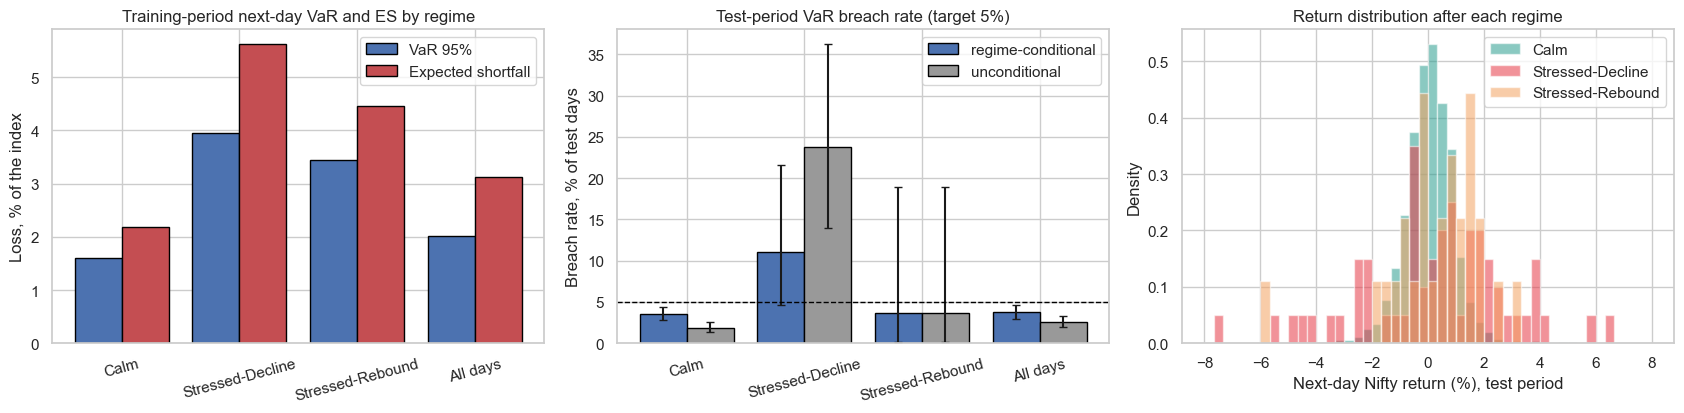

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
names = [REGIME_NAMES[k] for k in CLASSES] + ["All days"]
v_tr = [VAR[k] * 100 for k in CLASSES] + [VAR_ALL * 100]
e_tr = [var_table.loc[REGIME_NAMES[k], "ES 95% (next day) %"] for k in CLASSES] + [e_all * 100]
x_ = np.arange(4)
ax[0].bar(x_ - .2, v_tr, .4, color="#4c72b0", label="VaR 95%", edgecolor="black"); ax[0].bar(x_ + .2, e_tr, .4, color="#c44e52", label="Expected shortfall", edgecolor="black")
ax[0].set_xticks(x_); ax[0].set_xticklabels(names, rotation=15); ax[0].set_ylabel("Loss, % of the index"); ax[0].set_title("Training-period next-day VaR and ES by regime"); ax[0].legend()
cond = breach_table.xs("regime-conditional VaR", level=1); unc = breach_table.xs("unconditional VaR", level=1)
order = [REGIME_NAMES[k] for k in CLASSES] + ["All test days"]
for off, tab, col, lab in [(-.2, cond, "#4c72b0", "regime-conditional"), (.2, unc, "#999999", "unconditional")]:
    r_ = tab.loc[order, "breach rate %"].to_numpy(); lo_ = tab.loc[order, "95% CI low %"].to_numpy(); hi_ = tab.loc[order, "95% CI high %"].to_numpy()
    ax[1].bar(x_ + off, r_, .4, yerr=[r_ - lo_, hi_ - r_], capsize=3, color=col, label=lab, edgecolor="black")
ax[1].axhline(5, color="black", ls="--", lw=1); ax[1].set_xticks(x_); ax[1].set_xticklabels(names, rotation=15)
ax[1].set_ylabel("Breach rate, % of test days"); ax[1].set_title("Test-period VaR breach rate (target 5%)"); ax[1].legend()
for k in CLASSES:
    ax[2].hist(te_pairs.loc[te_pairs["prev_regime"] == k, "ret"] * 100, bins=np.linspace(-8, 8, 49), alpha=.55, color=COLORS[k], density=True, label=REGIME_NAMES[k])
ax[2].set_xlabel("Next-day Nifty return (%), test period"); ax[2].set_ylabel("Density"); ax[2].set_title("Return distribution after each regime"); ax[2].legend()
save_fig("var_by_regime")


**Interpretation (VaR by regime):**

| Training period, next day | Calm | Stressed-Decline | Stressed-Rebound | All days |
|---|---|---|---|---|
| VaR 95% | 1.60% | 3.95% | 3.44% | 2.01% |
| Expected shortfall 95% | 2.19% | 5.61% | 4.46% | 3.12% |
| Next-day volatility (daily) | 0.99% | 2.56% | 2.65% | 1.38% |

- **A stressed signal marks much riskier days.** After a Stressed-Decline signal the next-day VaR is about 2.5 times the Calm VaR, and in the test period 23.8% of the days that follow a Stressed-Decline signal lose more than 2%, against 1.9% after Calm. The regime therefore does carry information about **next-day risk**.
- **But it does not mark days with negative returns.** The average next-day return after a Stressed-Decline signal is **+0.05%** in the test period (+0.04% in training), no lower than after Calm (+0.04%), and after a Stressed-Rebound signal it is positive (+0.32%). Sitting in cash after a stressed signal removes risk, but it does not on average avoid losses. This is the key fact behind the Sharpe results in Section 5.
- **Calibration out of sample.** Over all test days the regime-conditional VaR is breached on 3.7% of days (95% interval 3.0% to 4.6%), a little conservative against the 5% target, and the single unconditional VaR on 2.5%. Both are conservative overall because the test period is calmer than the training period, which contains 2008-09. After Calm the breach rate is 3.5% (2.8% to 4.4%).
- **The stressed-regime VaR is too low out of sample.** After a Stressed-Decline signal the conditional VaR is breached on **11.1%** of days (7 of 63; interval 4.6% to 21.6%), more than twice the target. The unconditional VaR would be breached on 23.8% (15 of 63), so conditioning on the regime halves the error but does not remove it. For Stressed-Rebound there is 1 breach in 27 days (interval 0.1% to 19.0%), which is too few days to say anything.
- **Limits:** the stressed rows rest on 63 and 27 days, mostly from 2020, and breaches cluster in time, so the binomial intervals are optimistic.


#### 4. Strategy definitions and the backtest engine

**Objective:** turn each rule into an exposure series and measure it with one engine, so all strategies are treated identically.

For day *d*, the strategy holds exposure `e(d)` in the Nifty and `1 - e(d)` in cash:

`net return(d) = e(d) x Nifty return(d) + (1 - e(d)) x risk-free(d) - cost x |e(d) - e(d-1)|`

Every `e(d)` is a function of information at the close of day *d-1* only (`shift(1)`). The first position is established without cost for every strategy.

**Rival calibration (training period only, no tuning on results):**
- **VIX rule:** the cut-offs are percentiles of the training-period India VIX chosen so that the share of days in cash and at 50% equals S1's training shares (10.4% and 5.8%).
- **Volatility targeting:** target volatility solved on the training period so that its average exposure equals S1's. The exposure is `min(1, target / trailing 21-day volatility)`, never levered.
- **S2:** `min(1, VaR(Calm) / VaR(regime))` with the training VaR from Section 3.

In [6]:
MAPS = {"S1": {CALM: 1.0, REBOUND: 0.5, DECLINE: 0.0},          # primary
        "S1b": {CALM: 1.0, REBOUND: 0.5, DECLINE: 0.5}}          # two-tier rival
sig_regime = bt["regime"]                                            # signal known at the close of d
exposure_signal = {"S0 Buy-and-hold": pd.Series(1.0, index=bt.index),
                   "S1 Regime 100/50/0": sig_regime.map(MAPS["S1"]),
                   "S1b Regime 100/50/50": sig_regime.map(MAPS["S1b"]),
                   "S2 VaR-scaled": sig_regime.map({k: min(1.0, VAR[CALM] / VAR[k]) for k in CLASSES})}

# --- Rival A: VIX rule, cut-offs from the training period, sizes matched to S1's training time in each tier ---
tr_mask = bt.index <= pd.Timestamp("2017-12-28")                     # signal dates whose exposure falls inside the training period
share_cash = float((sig_regime[tr_mask] == DECLINE).mean()); share_half = float((sig_regime[tr_mask] == REBOUND).mean())
vix_cash_cut = float(bt.loc[tr_mask, "vix"].quantile(1 - share_cash))
vix_half_cut = float(bt.loc[tr_mask, "vix"].quantile(1 - share_cash - share_half))
vix_exposure = pd.Series(np.where(bt["vix"] > vix_cash_cut, 0.0, np.where(bt["vix"] > vix_half_cut, 0.5, 1.0)), index=bt.index)
exposure_signal["A VIX rule 100/50/0"] = vix_exposure

# --- Rival B: volatility targeting, target solved so that training-period average exposure equals S1's ---
s1_train_mean = float(exposure_signal["S1 Regime 100/50/0"][tr_mask].mean())
vol21 = bt["vol21"]
lo, hi = 0.01, 2.0
for _ in range(80):
    mid = (lo + hi) / 2
    if np.minimum(1.0, mid / vol21[tr_mask]).mean() < s1_train_mean: lo = mid
    else: hi = mid
VOL_TARGET = (lo + hi) / 2
exposure_signal["B Volatility targeting"] = np.minimum(1.0, VOL_TARGET / vol21)

print(f"S1 training-period shares: cash {share_cash:.3f}, 50% {share_half:.3f}, mean exposure {s1_train_mean:.3f}")
print(f"VIX rule: 0% above VIX {vix_cash_cut:.1f}; 50% between {vix_half_cut:.1f} and {vix_cash_cut:.1f}; else 100%   (training-period percentiles)")
print(f"Volatility target (annualised, solved on training period): {VOL_TARGET:.3f}")
print("S2 exposures:", {REGIME_NAMES[k]: round(min(1.0, VAR[CALM] / VAR[k]), 3) for k in CLASSES})

STRATS = list(exposure_signal)
def exposure_held(signal, delay=1):
    return signal.shift(delay)                                       # exposure held on day d uses the close of d-delay

def run_backtest(signal, cost_bps, rf=None, delay=1):
    e = exposure_held(signal, delay)
    rf_ = bt["rf"] if rf is None else rf
    e_prev = e.shift(1).fillna(e)                                    # first position without a trading cost
    net = e * bt["ret"] + (1 - e) * rf_ - cost_bps / 1e4 * (e - e_prev).abs()
    return net, e

def metrics(net, e, rf_series):
    net, e, rf_series = net.dropna(), e.loc[net.dropna().index], rf_series.loc[net.dropna().index]
    n = len(net); years = n / TD
    wealth = (1 + net).cumprod(); peak = np.maximum.accumulate(np.r_[1.0, wealth.to_numpy()])[1:]
    mdd = float((wealth.to_numpy() / peak - 1).min())
    ex = net - rf_series
    cagr = float(wealth.iloc[-1] ** (1 / years) - 1)
    de = e.diff().abs().fillna(0)
    return {"CAGR %": cagr * 100, "Volatility % (ann.)": net.std() * np.sqrt(TD) * 100, "Sharpe": ex.mean() / ex.std() * np.sqrt(TD),
            "Max drawdown %": mdd * 100, "Calmar": cagr / abs(mdd), "Turnover (x per year)": de.sum() / years,
            "Position changes": int((de > 1e-9).sum()), "Average exposure": float(e.mean()), "Final wealth (start = 1)": float(wealth.iloc[-1])}

# compute every strategy x cost; periods are slices of the same continuous series
net_all, exp_all = {}, {}
for s in STRATS:
    for c in COSTS_BPS:
        net_all[(s, c)], exp_all[(s, c)] = run_backtest(exposure_signal[s], c)
periods = {"Test 2018-2026 (out of sample)": bt.index > TRAIN_END, "Training 2008-2017 (in sample)": (bt.index <= TRAIN_END) & (bt.index >= START)}
rows = {}
for pname, mask in periods.items():
    for s in STRATS:
        for c in COSTS_BPS:
            n_, e_ = net_all[(s, c)][mask], exp_all[(s, c)][mask]
            rows[(pname, c, s)] = metrics(n_, e_, bt["rf"])
all_metrics = pd.DataFrame.from_dict(rows, orient="index"); all_metrics.index.names = ["period", "cost bps", "strategy"]
print()
print("Engine check: S0 at 0 bps equals plain buy-and-hold compounding on the test period:",
      bool(np.isclose((1 + net_all[("S0 Buy-and-hold", 0)][bt.index > TRAIN_END]).prod(), bt.loc[bt.index > TRAIN_END, "close"].iloc[-1] / bt["close"].loc[:TRAIN_END].iloc[-1])))

S1 training-period shares: cash 0.104, 50% 0.058, mean exposure 0.867
VIX rule: 0% above VIX 35.4; 50% between 29.5 and 35.4; else 100%   (training-period percentiles)
Volatility target (annualised, solved on training period): 0.163
S2 exposures: {'Calm': 1.0, 'Stressed-Decline': 0.406, 'Stressed-Rebound': 0.466}

Engine check: S0 at 0 bps equals plain buy-and-hold compounding on the test period: True


**Checks built into the engine:** S0 at 0 bps reproduces the plain price ratio of the index over the test period; every exposure uses `shift(1)`, so day *d*'s return is never used to set day *d*'s exposure; the first position is free for every strategy.

#### 5. Results: the test period (out of sample)

**Objective:** compare all strategies after the headline 10 bps cost, and then check how sensitive the picture is to costs, the risk-free rate and a one-day signal delay.

In [7]:
HEAD = (list(periods)[0], HEADLINE_COST)
head_tab = all_metrics.xs(HEAD[0], level="period").xs(HEAD[1], level="cost bps").reindex(STRATS)
print(f"TEST PERIOD, {HEADLINE_COST} bps one-way cost (headline)")
display(head_tab.round(2))
print("TEST PERIOD, all costs: Sharpe and maximum drawdown")
display(all_metrics.xs(HEAD[0], level="period")[["Sharpe", "Max drawdown %", "CAGR %", "Turnover (x per year)"]].round(2).unstack("cost bps").reindex(STRATS))

TEST PERIOD, 10 bps one-way cost (headline)


,CAGR %,Volatility % (ann.),Sharpe,Max drawdown %,Calmar,Turnover (x per year),Position changes,Average exposure,Final wealth (start = 1)
strategy,,,,,,,,,
S0 Buy-and-hold,9.34,16.86,0.29,-38.44,0.24,0.00,0,1.00,2.16
S1 Regime 100/50/0,8.67,13.82,0.27,-22.32,0.39,3.94,39,0.96,2.05
S1b Regime 100/50/50,8.89,14.58,0.28,-25.96,0.34,1.97,34,0.98,2.08
S2 VaR-scaled,8.83,14.32,0.28,-23.43,0.38,2.34,39,0.98,2.07
A VIX rule 100/50/0,9.34,14.17,0.31,-19.15,0.49,0.81,14,0.97,2.16
B Volatility targeting,7.65,13.54,0.21,-24.89,0.31,1.67,551,0.94,1.89


TEST PERIOD, all costs: Sharpe and maximum drawdown


Sharpe             Max drawdown %               CAGR %             Turnover (x per year)            
cost bps                   0     10    25             0      10     25     0     10    25                    0     10    25
strategy                                                                                                                   
S0 Buy-and-hold          0.29  0.29  0.29         -38.44 -38.44 -38.44   9.34  9.34  9.34                  0.00  0.00  0.00
S1 Regime 100/50/0       0.30  0.27  0.23         -21.32 -22.32 -23.82   9.10  8.67  8.03                  3.94  3.94  3.94
S1b Regime 100/50/50     0.30  0.28  0.26         -25.85 -25.96 -26.13   9.10  8.89  8.57                  1.97  1.97  1.97
S2 VaR-scaled            0.30  0.28  0.26         -23.30 -23.43 -23.64   9.09  8.83  8.45                  2.34  2.34  2.34
A VIX rule 100/50/0      0.32  0.31  0.31         -18.94 -19.15 -19.45   9.43  9.34  9.21                  0.81  0.81  0.81
B Volatility targeting   0.22  0.21  0.19         -24.81 -24.89 -25.00   7.83  7.65  7.38                  1.67  1.67  1.67

In [8]:
# Sensitivity 1: risk-free rate (0% and a flat 5%): affects the cash leg and the Sharpe ratio
sens = {}
test_mask = periods[list(periods)[0]]
for rf_name, rf_series in [("repo rate (headline)", bt["rf"]), ("0%", pd.Series(0.0, index=bt.index)), ("flat 5%", pd.Series(0.05 / TD, index=bt.index))]:
    for s in STRATS:
        n_, e_ = run_backtest(exposure_signal[s], HEADLINE_COST, rf=rf_series)
        m_ = metrics(n_[test_mask], e_[test_mask], rf_series)
        sens[(rf_name, s)] = {"Sharpe": m_["Sharpe"], "CAGR %": m_["CAGR %"], "Max drawdown %": m_["Max drawdown %"]}
sens = pd.DataFrame.from_dict(sens, orient="index"); sens.index.names = ["risk-free", "strategy"]
print("SENSITIVITY TO THE RISK-FREE RATE (test period, 10 bps)")
display(sens["Sharpe"].unstack("risk-free").reindex(STRATS).round(2))

# Sensitivity 2: execution delayed by one extra day
delay_rows = {}
for s in STRATS[1:]:
    n_, e_ = run_backtest(exposure_signal[s], HEADLINE_COST, delay=2)
    m_ = metrics(n_[test_mask], e_[test_mask], bt["rf"])
    delay_rows[s] = {"Sharpe (1-day lag)": head_tab.loc[s, "Sharpe"], "Sharpe (2-day lag)": m_["Sharpe"], "Max DD % (1-day lag)": head_tab.loc[s, "Max drawdown %"], "Max DD % (2-day lag)": m_["Max drawdown %"]}
print("SENSITIVITY TO AN EXTRA DAY OF SIGNAL DELAY (test period, 10 bps)")
display(pd.DataFrame.from_dict(delay_rows, orient="index").round(2))

SENSITIVITY TO THE RISK-FREE RATE (test period, 10 bps)


risk-free,0%,flat 5%,repo rate (headline)
strategy,,,
S0 Buy-and-hold,0.61,0.32,0.29
S1 Regime 100/50/0,0.66,0.31,0.27
S1b Regime 100/50/50,0.65,0.31,0.28
S2 VaR-scaled,0.66,0.31,0.28
A VIX rule 100/50/0,0.69,0.35,0.31
B Volatility targeting,0.59,0.24,0.21


SENSITIVITY TO AN EXTRA DAY OF SIGNAL DELAY (test period, 10 bps)


,Sharpe (1-day lag),Sharpe (2-day lag),Max DD % (1-day lag),Max DD % (2-day lag)
S1 Regime 100/50/0,0.27,0.29,-22.32,-20.07
S1b Regime 100/50/50,0.28,0.29,-25.96,-27.88
S2 VaR-scaled,0.28,0.29,-23.43,-25.78
A VIX rule 100/50/0,0.31,0.34,-19.15,-18.95
B Volatility targeting,0.21,0.24,-24.89,-25.14


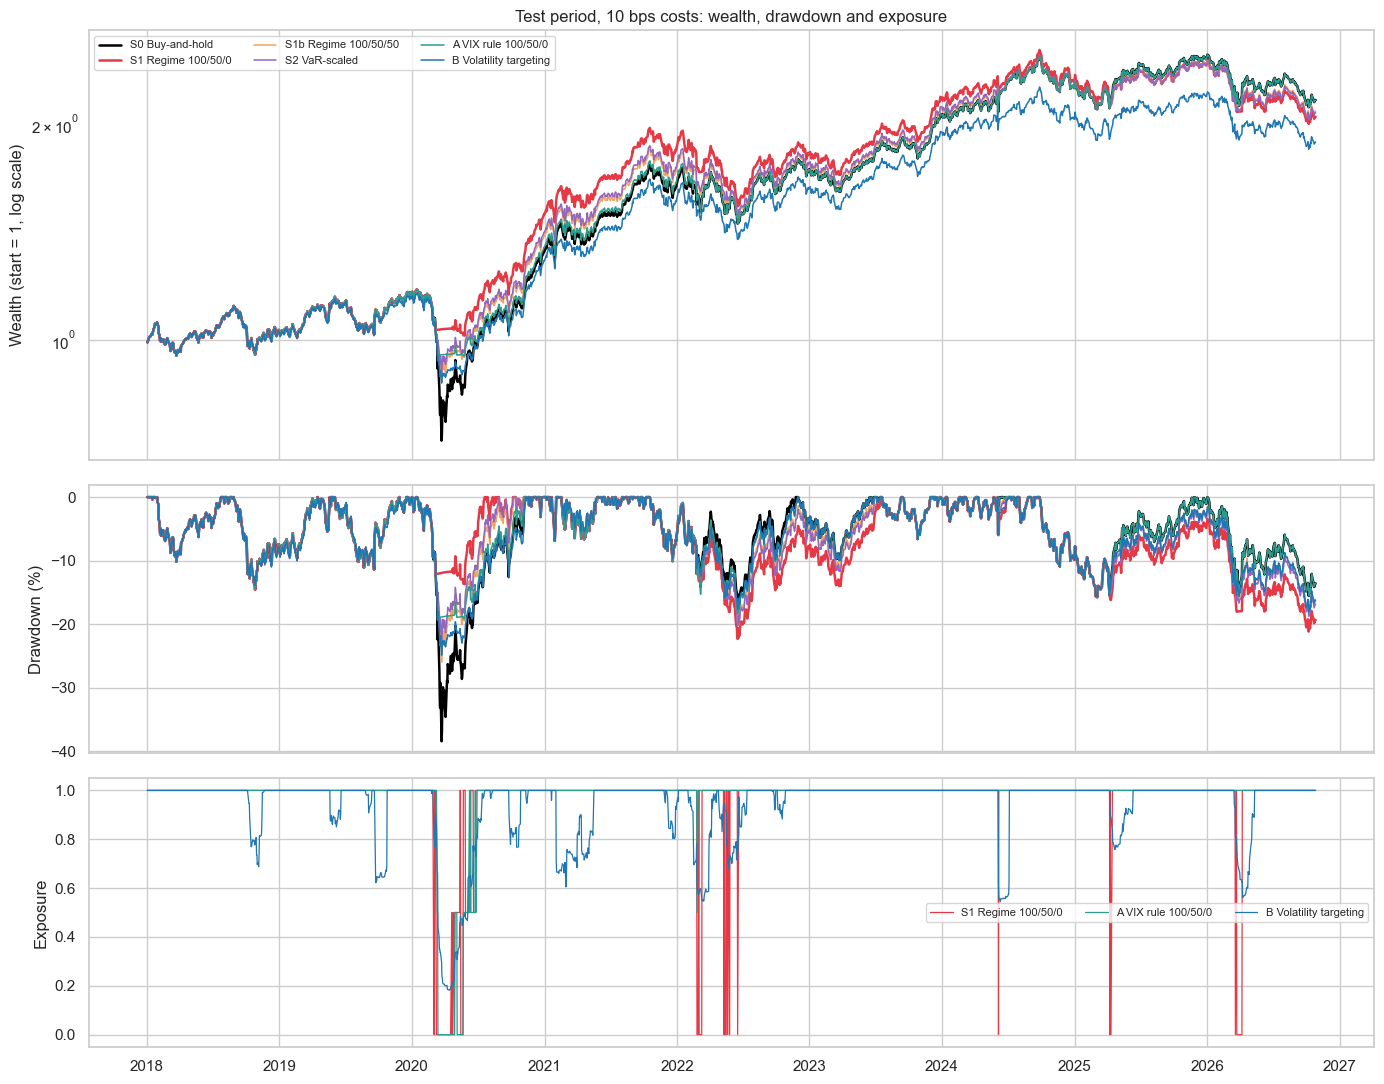

In [9]:
# Figure: wealth, drawdowns, exposure (test period, 10 bps)
test_idx = bt.index[test_mask]
COLS = {"S0 Buy-and-hold": "black", "S1 Regime 100/50/0": "#e63946", "S1b Regime 100/50/50": "#f4a261", "S2 VaR-scaled": "#9467bd",
        "A VIX rule 100/50/0": "#2a9d8f", "B Volatility targeting": "#1f77b4"}
fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True, gridspec_kw={"height_ratios": [1.6, 1, 1]})
for s in STRATS:
    w = (1 + net_all[(s, HEADLINE_COST)][test_idx]).cumprod()
    ax[0].plot(test_idx, w, label=s, color=COLS[s], lw=1.8 if s.startswith(("S0", "S1 ")) else 1.1)
    ax[1].plot(test_idx, (w / np.maximum.accumulate(w) - 1) * 100, color=COLS[s], lw=1.8 if s.startswith(("S0", "S1 ")) else 1.1)
ax[0].set_yscale("log"); ax[0].set_ylabel("Wealth (start = 1, log scale)"); ax[0].legend(ncol=3, fontsize=8); ax[0].set_title("Test period, 10 bps costs: wealth, drawdown and exposure")
ax[1].set_ylabel("Drawdown (%)")
for s in ["S1 Regime 100/50/0", "A VIX rule 100/50/0", "B Volatility targeting"]:
    ax[2].plot(test_idx, exp_all[(s, HEADLINE_COST)][test_idx], color=COLS[s], lw=.9, label=s)
ax[2].set_ylabel("Exposure"); ax[2].legend(ncol=3, fontsize=8); ax[2].set_ylim(-.05, 1.05)
save_fig("wealth_drawdown_exposure")

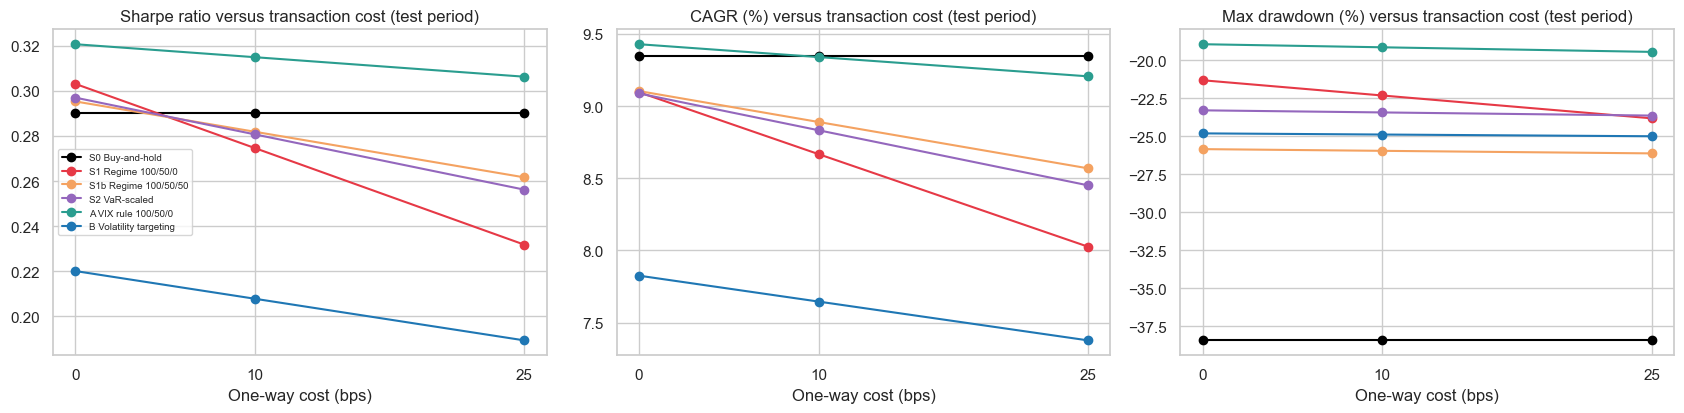

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for s in STRATS:
    sub = all_metrics.xs(HEAD[0], level="period").xs(s, level="strategy")
    ax[0].plot(sub.index, sub["Sharpe"], marker="o", color=COLS[s], label=s)
    ax[1].plot(sub.index, sub["CAGR %"], marker="o", color=COLS[s])
    ax[2].plot(sub.index, sub["Max drawdown %"], marker="o", color=COLS[s])
for a_, t in zip(ax, ["Sharpe ratio", "CAGR (%)", "Max drawdown (%)"]):
    a_.set_xlabel("One-way cost (bps)"); a_.set_title(t + " versus transaction cost (test period)"); a_.set_xticks(list(COSTS_BPS))
ax[0].legend(fontsize=7)
save_fig("cost_sensitivity")


**Interpretation (test period, 10 bps costs):**

| | CAGR | Volatility | Sharpe | Max drawdown | Calmar | Position changes |
|---|---|---|---|---|---|---|
| S0 Buy-and-hold | 9.34% | 16.9% | 0.29 | -38.4% | 0.24 | 0 |
| **S1 Regime 100/50/0** | 8.67% | 13.8% | 0.27 | **-22.3%** | 0.39 | 39 |
| S1b Regime 100/50/50 | 8.89% | 14.6% | 0.28 | -26.0% | 0.34 | 34 |
| S2 VaR-scaled | 8.83% | 14.3% | 0.28 | -23.4% | 0.38 | 39 |
| A VIX rule | 9.34% | 14.2% | **0.31** | **-19.2%** | **0.49** | 14 |
| B Volatility targeting | 7.65% | 13.5% | 0.21 | -24.9% | 0.31 | 551 |

1. **S1 reduces risk but does not improve risk-adjusted return.** Volatility falls from 16.9% to 13.8% and the maximum drawdown from -38.4% to -22.3% (Calmar 0.24 to 0.39), but the Sharpe ratio is 0.27 against 0.29 and the CAGR is 0.7 points lower. Before costs the Sharpe ratio is 0.30 against 0.29, so the loss comes from costs.
2. **Costs matter for S1.** It trades 39 times (about 3.9 times the portfolio per year). The CAGR is 9.10% at 0 bps, 8.67% at 10 bps and 8.03% at 25 bps; the Sharpe ratio falls from 0.30 to 0.27 to 0.23, below buy-and-hold's 0.29 at 25 bps. The drawdown barely changes with costs (-21.3% to -23.8%).
3. **A plain VIX rule beats S1 in the test period** on every measure: the same CAGR as buy-and-hold (9.34%), Sharpe 0.31, maximum drawdown -19.2% and only 14 position changes. **Caution:** the same rule was the worst strategy in the training period (Sharpe -0.06, CAGR 4.95%), because during 2008-09 the VIX stayed above the cut-off through the whole 2009 rebound and the rule sat in cash. A rule that wins out of sample and loses in sample is not strong evidence, and the test win rests largely on one crash.
4. **Volatility targeting is the weakest** (Sharpe 0.21, CAGR 7.65%) and rebalances almost daily (551 changes). Its calibration (equal average exposure to S1) and the no-leverage cap are my choices, so I would not read it as a general verdict on volatility targeting.
5. **The mapping matters for drawdown but not for Sharpe.** The two-tier S1b (-26.0%) and S2 (-23.4%) give smaller drawdown reductions than S1 and trade less, with Sharpe ratios of 0.28 for both.
6. **The risk-free rate drives the level of the Sharpe ratio.** With a 0% rate the Sharpe ratios are 0.61 (S0) and 0.66 (S1); with the repo rate 0.29 and 0.27; with a flat 5% 0.32 and 0.31. The headline Sharpe ratios are low partly because the Indian policy rate (4% to 9%) is high relative to a **price** index that excludes dividends.
7. **An extra day of delay did not hurt S1** (Sharpe 0.27 to 0.29, drawdown -22.3% to -20.1%), the opposite of what I expected. The weakness is therefore not slow detection but **whipsaw**: signals reverse within a day or two (Phase 7: median Stressed-Decline episode of 2 sessions), and a delayed signal avoids some of those reversals. I would treat this as noise, but it gives no sign that faster detection would help.
8. **The wealth chart shows where the gain comes from.** S1 sits well above buy-and-hold from the March 2020 crash until about 2022. After that its drawdowns are *deeper* than buy-and-hold's (2022 and 2024 to 2026), because of one-day flips to cash (the spikes to zero in the exposure panel). Final wealth is 2.05 for S1 against 2.16 for buy-and-hold.


#### 6. Uncertainty: paired block bootstrap and the success criterion

**Objective:** decide how much of any difference could be sampling noise. Strategy returns are resampled in **21-session blocks** (the same days for both strategies in a pair), 2,000 draws, on the test period at 10 bps. Maximum drawdown is computed on each resampled path; stitching blocks breaks long-range structure, so those intervals are approximate. The test period contains essentially one large crisis, so these intervals describe sampling variation, **not** the uncertainty about whether another crisis would behave the same way.

In [11]:
def circular_blocks(n, rng, block=BLOCK):
    nb = int(np.ceil(n / block))
    return ((rng.integers(0, n, nb)[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]

net_te = pd.DataFrame({s: net_all[(s, HEADLINE_COST)][test_mask] for s in STRATS})
rf_te = bt.loc[test_mask, "rf"].to_numpy()
R = net_te.to_numpy(); n_te = len(R)
rng = np.random.default_rng(SEED)
sharpe_b = np.empty((N_BOOT, len(STRATS))); mdd_b = np.empty((N_BOOT, len(STRATS)))
for b in range(N_BOOT):
    idx = circular_blocks(n_te, rng)
    x, ex = R[idx], R[idx] - rf_te[idx][:, None]
    sharpe_b[b] = ex.mean(axis=0) / ex.std(axis=0, ddof=1) * np.sqrt(TD)
    w = np.cumprod(1 + x, axis=0); pk = np.maximum.accumulate(np.vstack([np.ones(len(STRATS)), w]), axis=0)[1:]
    mdd_b[b] = (w / pk - 1).min(axis=0)
col = {s: i for i, s in enumerate(STRATS)}
pt = {s: head_tab.loc[s] for s in STRATS}

pairs_ = [("S1 Regime 100/50/0", "S0 Buy-and-hold"), ("S1b Regime 100/50/50", "S0 Buy-and-hold"), ("S2 VaR-scaled", "S0 Buy-and-hold"),
          ("A VIX rule 100/50/0", "S0 Buy-and-hold"), ("B Volatility targeting", "S0 Buy-and-hold"),
          ("S1 Regime 100/50/0", "A VIX rule 100/50/0"), ("S1 Regime 100/50/0", "B Volatility targeting")]
rows = {}
for a, b in pairs_:
    ds = sharpe_b[:, col[a]] - sharpe_b[:, col[b]]
    dd_red = (1 - mdd_b[:, col[a]] / mdd_b[:, col[b]]) * 100                       # % reduction of max drawdown of a vs b
    lo, hi = np.percentile(ds, [2.5, 97.5]); lo2, hi2 = np.percentile(dd_red, [2.5, 97.5])
    rows[f"{a}  minus  {b}"] = {"Sharpe difference": pt[a]["Sharpe"] - pt[b]["Sharpe"], "Sharpe 95% CI": f"[{lo:+.2f}, {hi:+.2f}]", "interval excludes 0": bool(lo > 0 or hi < 0),
                                "Max-drawdown reduction % (point)": (1 - pt[a]["Max drawdown %"] / pt[b]["Max drawdown %"]) * 100, "Max-drawdown reduction % 95% CI": f"[{lo2:.0f}, {hi2:.0f}]"}
boot_table = pd.DataFrame.from_dict(rows, orient="index")
print(f"PAIRED CIRCULAR BLOCK BOOTSTRAP ({N_BOOT} draws, block {BLOCK}, seed {SEED}), test period, 10 bps")
display(boot_table.round(2))

# ---- pre-registered success criterion for S1 ----
s1, s0 = "S1 Regime 100/50/0", "S0 Buy-and-hold"
dd_reduction = (1 - pt[s1]["Max drawdown %"] / pt[s0]["Max drawdown %"]) * 100
ds1 = sharpe_b[:, col[s1]] - sharpe_b[:, col[s0]]
sh_lo, sh_hi = np.percentile(ds1, [2.5, 97.5])
crit_a, crit_b = bool(dd_reduction >= 25), bool(sh_hi >= 0)
print()
print("PRE-REGISTERED SUCCESS CRITERION FOR S1 (test period, 10 bps)")
print(f"  (a) maximum drawdown at least 25% smaller than buy-and-hold: S1 {pt[s1]['Max drawdown %']:.1f}% vs S0 {pt[s0]['Max drawdown %']:.1f}% -> reduction {dd_reduction:.1f}%  -> {'PASS' if crit_a else 'FAIL'}")
print(f"  (b) Sharpe difference vs buy-and-hold not significantly below zero: {pt[s1]['Sharpe'] - pt[s0]['Sharpe']:+.2f}, 95% CI [{sh_lo:+.2f}, {sh_hi:+.2f}] -> {'PASS' if crit_b else 'FAIL'}")
print(f"  OVERALL: {'S1 WORKS under the pre-registered criterion' if crit_a and crit_b else 'S1 DOES NOT MEET the pre-registered criterion'}")

PAIRED CIRCULAR BLOCK BOOTSTRAP (2000 draws, block 21, seed 42), test period, 10 bps


,Sharpe difference,Sharpe 95% CI,interval excludes 0,Max-drawdown reduction % (point),Max-drawdown reduction % 95% CI
S1 Regime 100/50/0 minus S0 Buy-and-hold,-0.02,"[-0.34, +0.38]",False,41.94,"[-25, 60]"
S1b Regime 100/50/50 minus S0 Buy-and-hold,-0.01,"[-0.17, +0.17]",False,32.46,"[-10, 39]"
S2 VaR-scaled minus S0 Buy-and-hold,-0.01,"[-0.21, +0.21]",False,39.04,"[-12, 45]"
A VIX rule 100/50/0 minus S0 Buy-and-hold,0.02,"[-0.24, +0.29]",False,50.19,"[-10, 50]"
B Volatility targeting minus S0 Buy-and-hold,-0.08,"[-0.27, +0.11]",False,35.25,"[-10, 41]"
S1 Regime 100/50/0 minus A VIX rule 100/50/0,-0.04,"[-0.21, +0.16]",False,-16.57,"[-25, 31]"
S1 Regime 100/50/0 minus B Volatility targeting,0.07,"[-0.14, +0.35]",False,10.33,"[-26, 42]"



PRE-REGISTERED SUCCESS CRITERION FOR S1 (test period, 10 bps)
  (a) maximum drawdown at least 25% smaller than buy-and-hold: S1 -22.3% vs S0 -38.4% -> reduction 41.9%  -> PASS
  (b) Sharpe difference vs buy-and-hold not significantly below zero: -0.02, 95% CI [-0.34, +0.38] -> PASS
  OVERALL: S1 WORKS under the pre-registered criterion


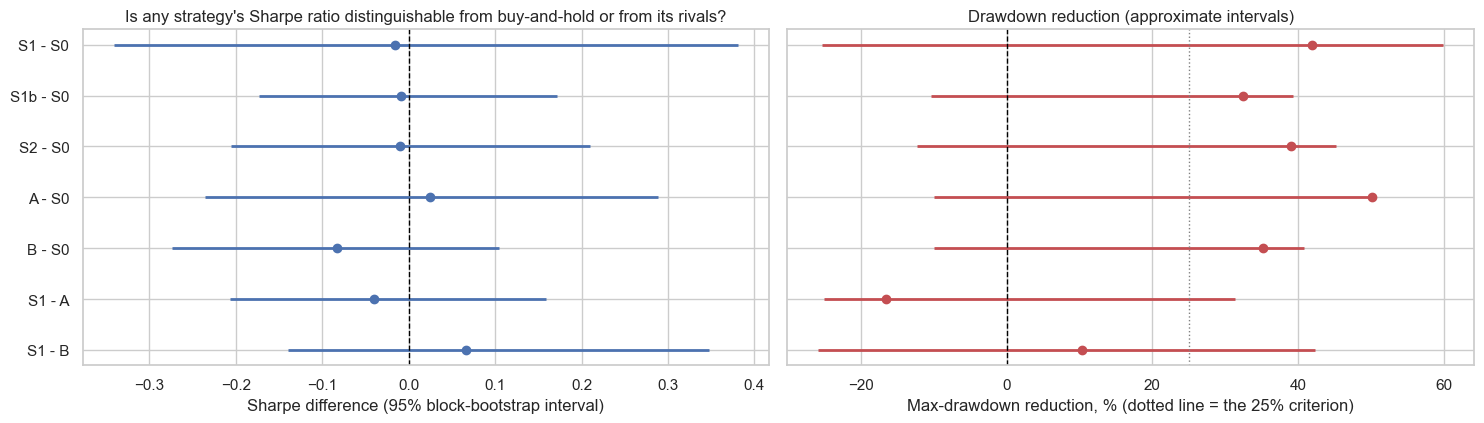

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for i, (a, b) in enumerate(pairs_):
    ds = sharpe_b[:, col[a]] - sharpe_b[:, col[b]]
    lo, hi = np.percentile(ds, [2.5, 97.5]); p = pt[a]["Sharpe"] - pt[b]["Sharpe"]
    ax[0].hlines(i, lo, hi, color="#4c72b0", lw=2); ax[0].plot(p, i, "o", color="#4c72b0")      # interval and point estimate (the point can sit outside a percentile interval)
ax[0].axvline(0, color="black", ls="--", lw=1); ax[0].set_yticks(range(len(pairs_)))
ax[0].set_yticklabels([f"{a.split(' ')[0]} - {b.split(' ')[0]}" for a, b in pairs_]); ax[0].invert_yaxis()
ax[0].set_xlabel("Sharpe difference (95% block-bootstrap interval)"); ax[0].set_title("Is any strategy's Sharpe ratio distinguishable from buy-and-hold or from its rivals?")
for i, (a, b) in enumerate(pairs_):
    dd = (1 - mdd_b[:, col[a]] / mdd_b[:, col[b]]) * 100
    lo, hi = np.percentile(dd, [2.5, 97.5]); p = (1 - pt[a]["Max drawdown %"] / pt[b]["Max drawdown %"]) * 100
    ax[1].hlines(i, lo, hi, color="#c44e52", lw=2); ax[1].plot(p, i, "o", color="#c44e52")
ax[1].axvline(0, color="black", ls="--", lw=1); ax[1].axvline(25, color="grey", ls=":", lw=1); ax[1].set_yticks(range(len(pairs_))); ax[1].set_yticklabels([""] * len(pairs_)); ax[1].invert_yaxis()
ax[1].set_xlabel("Max-drawdown reduction, % (dotted line = the 25% criterion)"); ax[1].set_title("Drawdown reduction (approximate intervals)")
save_fig("bootstrap")


**Interpretation (uncertainty and the pre-registered criterion):**

**Result of the criterion fixed in advance (test period, 10 bps):**
- (a) Maximum drawdown at least 25% smaller than buy-and-hold: -22.3% against -38.4%, a **41.9% reduction: pass**.
- (b) Sharpe difference versus buy-and-hold not significantly below zero: -0.02, 95% interval [-0.34, +0.38]: **pass**.
- **Overall: S1 meets the pre-registered criterion.**

**How much weight this deserves:**
- **Part (b) is a weak bar.** The interval is about 0.7 wide, so it cannot tell "no different" from "much better" or "much worse". The correct reading is: there is **no evidence that S1 improves the Sharpe ratio**, and no evidence that it hurts it.
- **Part (a) is a point estimate on one path.** The bootstrap interval for the drawdown reduction is [-25%, +60%] (approximate, because stitched blocks break long-range structure). It includes zero, so even the drawdown benefit is not statistically secure; it depends on the single 2020 crash.
- **No strategy is distinguishable from buy-and-hold on Sharpe**, and S1 is not distinguishable from either rival: S1 minus VIX rule -0.04 [-0.21, +0.16], S1 minus volatility targeting +0.07 [-0.14, +0.35]. On drawdown the VIX rule is ahead of S1 by 16.6 points of reduction (point estimate; interval [-25, +31]). The test period simply cannot rank these strategies.
- The test period contains essentially **one** large crisis, so these intervals describe sampling variation within that history, not the risk that the next crisis behaves differently.


#### 7. Behaviour inside 2020 and 2022 (outline task 9.6)

**Objective:** look at the two stress episodes separately, because one aggregate Sharpe ratio can hide where the strategy helped and where it cost money. For each window: the total return of each strategy and the maximum drawdown reached inside it (10 bps costs; the drawdown is measured from the start of the window).

strategy,S0 Buy-and-hold,S1 Regime 100/50/0,S1b Regime 100/50/50,S2 VaR-scaled,A VIX rule 100/50/0,B Volatility targeting
window,,,,,,
2020 crash (20 Feb to 23 Mar),-37.2,-10.2,-24.5,-21.9,-17.3,-23.4
2020 full calendar year,14.9,29.4,20.7,22.1,16.4,13.0
2020 rebound (24 Mar to 30 Jun),35.4,6.6,18.3,15.7,4.1,11.6
2022 H1 selloff (3 Jan to 17 Jun),-11.9,-17.3,-14.6,-15.1,-13.0,-12.2
2022 full calendar year,4.3,-2.2,1.1,0.4,2.9,3.3


strategy,S0 Buy-and-hold,S1 Regime 100/50/0,S1b Regime 100/50/50,S2 VaR-scaled,A VIX rule 100/50/0,B Volatility targeting
window,,,,,,
2020 crash (20 Feb to 23 Mar),-37.2,-10.4,-24.5,-21.9,-17.4,-23.4
2020 full calendar year,-38.4,-13.7,-26.0,-23.4,-19.1,-24.9
2020 rebound (24 Mar to 30 Jun),-10.5,-4.9,-5.6,-5.1,-3.1,-4.2
2022 H1 selloff (3 Jan to 17 Jun),-16.5,-21.6,-19.0,-19.5,-17.6,-16.7
2022 full calendar year,-16.5,-21.6,-19.0,-19.5,-17.6,-16.7


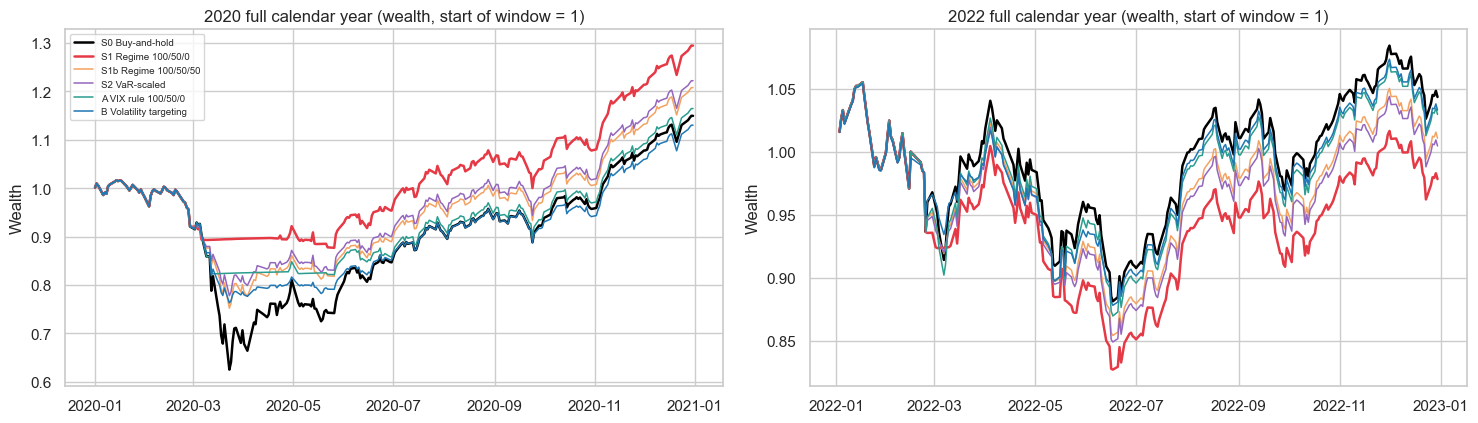

In [13]:
WINDOWS = [("2020 crash (20 Feb to 23 Mar)", "2020-02-20", "2020-03-23"), ("2020 rebound (24 Mar to 30 Jun)", "2020-03-24", "2020-06-30"),
           ("2020 full calendar year", "2020-01-01", "2020-12-31"), ("2022 H1 selloff (3 Jan to 17 Jun)", "2022-01-03", "2022-06-17"),
           ("2022 full calendar year", "2022-01-01", "2022-12-31")]
rows = {}
for wname, a, b in WINDOWS:
    for s in STRATS:
        r_ = net_all[(s, HEADLINE_COST)].loc[a:b]; w = (1 + r_).cumprod()
        rows[(wname, s)] = {"total return %": (w.iloc[-1] - 1) * 100, "max drawdown in window %": (w / np.maximum.accumulate(np.r_[1.0, w.to_numpy()])[1:] - 1).min() * 100,
                            "average exposure": exp_all[(s, HEADLINE_COST)].loc[a:b].mean()}
win_table = pd.DataFrame.from_dict(rows, orient="index"); win_table.index.names = ["window", "strategy"]
display(win_table["total return %"].unstack("strategy")[STRATS].round(1))
display(win_table["max drawdown in window %"].unstack("strategy")[STRATS].round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax_, (wname, a, b) in zip(axes, [WINDOWS[2], WINDOWS[4]]):
    for s in STRATS:
        w = (1 + net_all[(s, HEADLINE_COST)].loc[a:b]).cumprod()
        ax_.plot(w.index, w, color=COLS[s], lw=1.8 if s.startswith(("S0", "S1 ")) else 1.1, label=s)
    ax_.set_title(wname + " (wealth, start of window = 1)"); ax_.set_ylabel("Wealth")
axes[0].legend(fontsize=7)
save_fig("stress_windows")


**Interpretation (2020 and 2022):**

| Total return in window (10 bps) | S0 | S1 | S1b | S2 | VIX rule | Vol. target |
|---|---|---|---|---|---|---|
| 2020 crash (20 Feb to 23 Mar) | -37.2% | **-10.2%** | -24.5% | -21.9% | -17.3% | -23.4% |
| 2020 rebound (24 Mar to 30 Jun) | +35.4% | +6.6% | +18.3% | +15.7% | +4.1% | +11.6% |
| 2020 calendar year | +14.9% | **+29.4%** | +20.7% | +22.1% | +16.4% | +13.0% |
| 2022 H1 selloff (3 Jan to 17 Jun) | -11.9% | **-17.3%** | -14.6% | -15.1% | -13.0% | -12.2% |
| 2022 calendar year | +4.3% | **-2.2%** | +1.1% | +0.4% | +2.9% | +3.3% |

- **2020 is where the regime layer earns its keep.** The Stressed-Decline signal moved S1 to cash through most of the crash (-10.2% against -37.2%; maximum drawdown in the window -10.4% against -37.2%). It then missed most of the rebound (+6.6% against +35.4% from 24 March to 30 June, as it stayed in cash or at 50% through the rebound), yet over the whole calendar year S1 returned +29.4% against +14.9%, because avoiding the crash mattered more.
- **2022 is where it loses.** In the slow, moderate-volatility selloff of the first half of 2022, S1 lost 17.3% against 11.9% for buy-and-hold (maximum drawdown -21.6% against -16.5%), and -2.2% against +4.3% over the year. The regime flagged only short stressed spells (for example six sessions from 2 March), so the strategy repeatedly sold into dips and bought back after the bounce. This is the flicker problem from Phase 7 showing up in money. The VIX rule (-13.0%) and volatility targeting (-12.2%) did better.
- **So the evidence is one sharp crash (helps) and one choppy decline (hurts).** Two episodes cannot establish which behaviour is typical, but they match the mechanism: the regime layer helps when stress is sudden and sustained, and hurts when stress is brief and noisy.


#### 8. Training period (in sample) and saving the outputs

The training-period results are shown for completeness only: the labels, VaR, VIX cut-offs and volatility target were all estimated on these dates, so they overstate what could have been achieved in real time.

In [14]:
print("TRAINING PERIOD (2008-06-10 to 2017-12-29): IN SAMPLE, 10 bps")
display(all_metrics.xs(list(periods)[1], level="period").xs(HEADLINE_COST, level="cost bps").reindex(STRATS)[["CAGR %", "Volatility % (ann.)", "Sharpe", "Max drawdown %", "Calmar", "Turnover (x per year)", "Average exposure"]].round(2))

# ---- save ----
daily = pd.DataFrame({"regime": bt["regime"], "nifty_return": bt["ret"], "risk_free_daily": bt["rf"], "split": np.where(bt.index <= TRAIN_END, "train", "test")})
for s in STRATS:
    key = s.split(" ")[0]
    daily[f"exposure_{key}"] = exp_all[(s, HEADLINE_COST)]
    daily[f"net_return_{key}_10bps"] = net_all[(s, HEADLINE_COST)]
daily.iloc[1:].round(8).to_csv(PROC / "backtest_daily_returns.csv", index_label="Date")
all_metrics.round(6).to_csv(PROC / "backtest_metrics.csv")
var_table.round(6).to_csv(PROC / "backtest_var_by_regime.csv", index_label="regime")
breach_table.round(6).to_csv(PROC / "backtest_var_breaches_test.csv")
boot_table.to_csv(PROC / "backtest_bootstrap.csv", index_label="comparison")
win_table.round(6).to_csv(PROC / "backtest_event_windows.csv")
sens.round(6).to_csv(PROC / "backtest_rf_sensitivity.csv")
pd.DataFrame.from_dict(delay_rows, orient="index").round(6).to_csv(PROC / "backtest_delay_sensitivity.csv", index_label="strategy")
config = {"seed": SEED, "signal_timing": "regime at close of d-1 sets exposure on day d", "headline_cost_bps": HEADLINE_COST, "costs_bps": list(COSTS_BPS),
          "risk_free": "RBI repo rate (macro.csv risk_free_daily)", "maps": {k: {REGIME_NAMES[r]: v for r, v in m.items()} for k, m in MAPS.items()},
          "var_training_95_next_day": {REGIME_NAMES[k]: VAR[k] for k in CLASSES} | {"unconditional": VAR_ALL},
          "vix_cut_offs": {"cash_above": vix_cash_cut, "half_between": [vix_half_cut, vix_cash_cut]}, "vol_target_annualised": VOL_TARGET,
          "bootstrap": {"draws": N_BOOT, "block": BLOCK}, "success_criterion": "test, 10 bps: max drawdown >= 25% smaller than S0 and Sharpe-difference 95% CI not entirely below 0",
          "criterion_result": {"drawdown_reduction_pct": float(dd_reduction), "sharpe_diff_ci": [float(sh_lo), float(sh_hi)], "passed": bool(crit_a and crit_b)}}
with open(PROC / "backtest_config.json", "w") as f:
    json.dump(config, f, indent=2)

# ---- final checks ----
chk = pd.read_csv(PROC / "backtest_daily_returns.csv", index_col="Date", parse_dates=True)
assert chk.index.is_unique and chk.index.is_monotonic_increasing and chk.isna().sum().sum() == 0
assert (chk["exposure_S0"] == 1).all() and chk[[c for c in chk if c.startswith("exposure_")]].min().min() >= 0 and chk[[c for c in chk if c.startswith("exposure_")]].max().max() <= 1
# no look-ahead: the exposure on a date must equal the exposure rule applied to the PREVIOUS date's signal
assert np.allclose(chk["exposure_S1"].to_numpy()[1:], bt["regime"].map(MAPS["S1"]).shift(1).loc[chk.index].to_numpy()[1:])
assert pd.read_csv(PROC / "regimes.csv", index_col="Date", parse_dates=True)["regime"].equals(regimes["regime"])
print("All checks passed: exposures in [0, 1], no missing values, exposure = rule applied to the previous close, regimes.csv untouched.")
print("Saved:", *sorted(p.name for p in PROC.glob("backtest_*")), sep="\n  ")

TRAINING PERIOD (2008-06-10 to 2017-12-29): IN SAMPLE, 10 bps


,CAGR %,Volatility % (ann.),Sharpe,Max drawdown %,Calmar,Turnover (x per year),Average exposure
strategy,,,,,,,
S0 Buy-and-hold,9.61,21.93,0.21,-45.75,0.21,0.00,1.00
S1 Regime 100/50/0,8.31,15.21,0.15,-28.17,0.30,6.26,0.87
S1b Regime 100/50/50,8.57,16.56,0.16,-27.73,0.31,2.75,0.92
S2 VaR-scaled,8.46,16.01,0.16,-27.46,0.31,3.36,0.91
A VIX rule 100/50/0,4.95,14.90,-0.06,-32.92,0.15,4.48,0.87
B Volatility targeting,8.10,15.00,0.13,-26.07,0.31,2.74,0.87


All checks passed: exposures in [0, 1], no missing values, exposure = rule applied to the previous close, regimes.csv untouched.
Saved:
  backtest_bootstrap.csv
  backtest_config.json
  backtest_daily_returns.csv
  backtest_delay_sensitivity.csv
  backtest_event_windows.csv
  backtest_metrics.csv
  backtest_rf_sensitivity.csv
  backtest_var_breaches_test.csv
  backtest_var_by_regime.csv


#### 9. Conclusion and report

**The claim tested (problem statement (c)):** does a simple regime-aware exposure rule give better risk-adjusted performance than buy-and-hold on the Nifty 50, out of sample and after costs?

**Answer: partly, and not convincingly.**
- **Drawdown: yes, in this sample.** S1's maximum drawdown is -22.3% against -38.4% (a 42% reduction), and volatility falls from 16.9% to 13.8%. The S1 rule meets the success criterion fixed in advance. **But** the gain comes from one event (the 2020 crash), and its bootstrap interval includes zero.
- **Sharpe ratio: no improvement.** 0.27 against 0.29 after 10 bps (0.30 before costs), with an interval of [-0.34, +0.38]. At 25 bps S1 is below buy-and-hold.
- **Against simple rivals: not better.** A VIX rule with the same exposure tiers had the same CAGR as buy-and-hold, a Sharpe ratio of 0.31, a smaller drawdown (-19.2%) and a third of the trades. It was the worst strategy in the training period, so its test result is not robust either, but it means **the regime layer is not shown to add value beyond a simple volatility indicator**, consistent with the Phase 7 finding.
- **Where it works and where it fails:** it helps in sharp, sustained stress (2020) and hurts in choppy declines (2022) because Stressed-Decline flickers.

**Why the Sharpe ratio does not improve (Section 3):** the days after a stressed signal are much riskier (VaR about 2.5 times higher) but do not have lower average returns, so cutting exposure removes risk without avoiding losses, and it forgoes rebounds and pays costs.

**Strengths:** timing is strictly lagged by one day; all parameters are estimated on the training period; costs, the risk-free rate and a signal delay were stress-tested; the success criterion was fixed before any result; rivals and bootstrap intervals are reported.

**Limitations to state:**
- One large crisis in the test period; the confidence intervals are wide and probably still too narrow.
- The regimes and every parameter come from 2008-2017, so the training-period results are in sample.
- Nifty is a price index (no dividends) and the risk-free rate is the repo rate, a proxy.
- Costs are a simple proportional model; no market impact or taxes.
- Not done: T2 basket VaR for the 15 stocks (9.8) and a classifier-driven backtest (identical to S1 for the selected classifiers, per Phase 8).

**What I would do next (to be fixed in advance, not tuned on these results):**
1. **A persistence filter on the signal:** change exposure only after the new regime has held for two consecutive sessions. It targets the whipsaw directly and is justified by the Phase 7 episode lengths, not by this backtest.
2. **Walk-forward regimes**, so the labels and the parameters are out of sample for the whole period.
3. Re-run Phase 9 on both, reporting the original results beside them.
